# Check 6: Diagnostic plots before PyVista

This notebook plots actual recorded model data before adding a 3D display or a light field. A smooth animation can hide missing records, implausible spacing or a misleading state label; explicit time series expose those issues.

Polarization and rotation measure different aspects of order. Mean nearest-neighbour distance measures local spacing, while mean distance to the centroid measures overall spread. Inspecting all four prevents a compact group from being confused with an aligned but dispersed one. [Tunstrøm et al. (2013)](https://doi.org/10.1371/journal.pcbi.1002915) also analyses the polarization–rotation state space.

The following plots show the raw per-step measurements of this deterministic, constant-speed social baseline. They are not temporally smoothed experimental trajectories. No PyVista, light field or gradient direction is used.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "shiner_model.py").is_file()
)
MODEL_DIR = PROJECT_ROOT
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

from shiner_model import GoldenShinersModel, classify_collective_state
from checks.check_support import run_model, audit_run

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

FIGURE_DIR = Path(PROJECT_ROOT / "checks" / "figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

## Time series across three seeds

We use seeds 0, 1 and 7, 20 fish, and 500 steps. The horizontal axis is **simulated time = recorded step × dt**, not the DataFrame row number or wall-clock execution time. Each curve includes the state at t=0. The dashed reference lines on the order parameters show the baseline cutoffs; a state label depends on both parameters together.

In [2]:
SEEDS = [0, 1, 7]
STEPS = 500
plot_models = {}
plot_frames = {}
plot_audits = []
for seed in SEEDS:
    case = run_model(n_fish=20, seed=seed, steps=STEPS)
    plot_models[seed] = case
    plot_frames[seed] = case.datacollector.get_model_vars_dataframe()
    plot_audits.append({"Seed": seed, **audit_run(case)})
pd.DataFrame(plot_audits)

,Seed,Fish,Steps,Model rows,Agent rows,Result
0,0,20,500,501,10020,passed
1,1,20,500,501,10020,passed
2,7,20,500,501,10020,passed


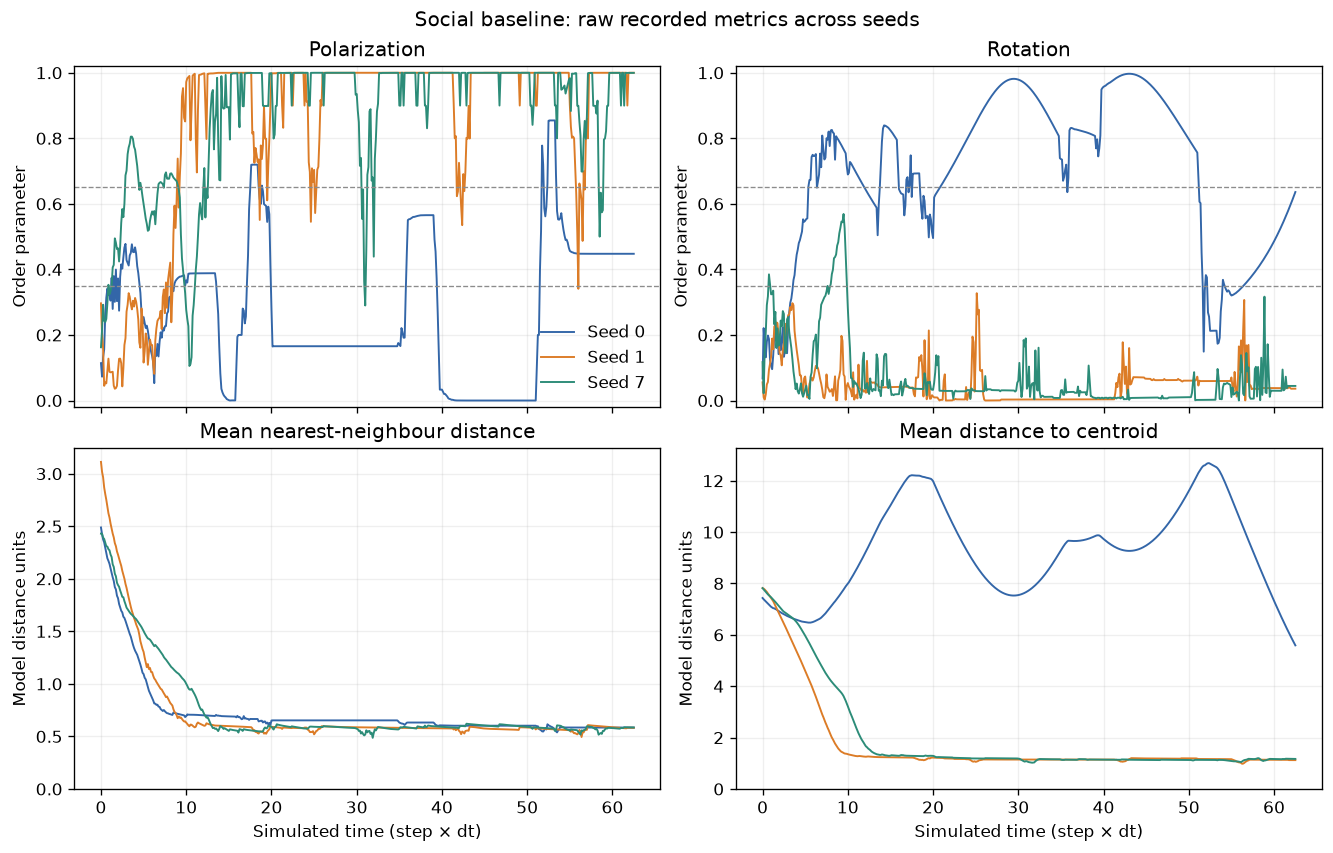

In [3]:
metrics = [
    ("Polarization", "Polarization", "Order parameter"),
    ("Rotation", "Rotation", "Order parameter"),
    ("MeanNND", "Mean nearest-neighbour distance", "Model distance units"),
    ("MeanDistanceToCentroid", "Mean distance to centroid", "Model distance units"),
]
colors = dict(zip(SEEDS, ["#3366a8", "#dc7c27", "#2c8c78"]))
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, constrained_layout=True)
for axis, (metric, title, ylabel) in zip(axes.flat, metrics):
    for seed in SEEDS:
        frame = plot_frames[seed]
        time = frame.index.to_numpy() * plot_models[seed].dt
        axis.plot(time, frame[metric], label=f"Seed {seed}", color=colors[seed], linewidth=1.15)
    if metric in ("Polarization", "Rotation"):
        axis.axhline(0.35, color="0.55", linestyle="--", linewidth=0.8)
        axis.axhline(0.65, color="0.55", linestyle="--", linewidth=0.8)
        axis.set_ylim(-0.02, 1.02)
    else:
        axis.set_ylim(bottom=0)
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.grid(alpha=0.2)
for axis in axes[-1]:
    axis.set_xlabel("Simulated time (step × dt)")
axes[0, 0].legend(loc="best", frameon=False)
fig.suptitle("Social baseline: raw recorded metrics across seeds")
fig.savefig(FIGURE_DIR / "06_metric_time_series.png", dpi=180)
plt.show()

## Polarization–rotation state space

Seed 1 is shown as one trajectory in the P/R plane, coloured by simulated time. The shaded corner regions show the implemented baseline labels. The white region is `transition`. The start and final markers distinguish initial disorder from later behaviour.

This plot is informative because a run can move between regions without any change to its interaction rules. Labels summarize where the measurements lie; they do not explain the mechanism or demonstrate a stable collective state.

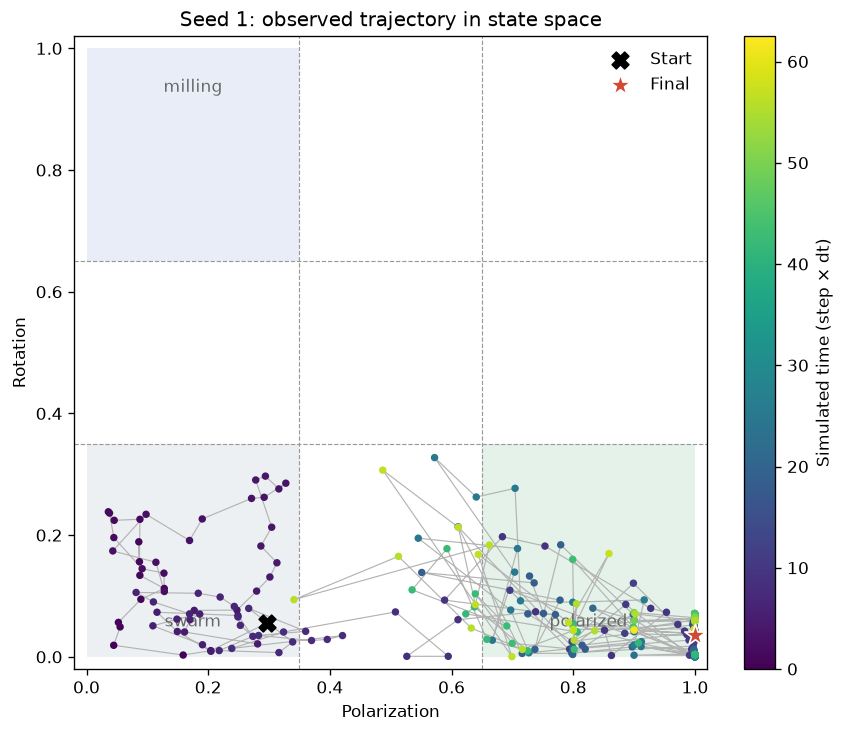

In [4]:
SELECTED_SEED = 1
selected = plot_frames[SELECTED_SEED]
selected_model = plot_models[SELECTED_SEED]
time = selected.index.to_numpy() * selected_model.dt
fig, axis = plt.subplots(figsize=(7, 6), constrained_layout=True)
axis.add_patch(Rectangle((0, 0), 0.35, 0.35, facecolor="#edf0f3", edgecolor="none"))
axis.add_patch(Rectangle((0.65, 0), 0.35, 0.35, facecolor="#e4f2e9", edgecolor="none"))
axis.add_patch(Rectangle((0, 0.65), 0.35, 0.35, facecolor="#e9edf8", edgecolor="none"))
axis.text(0.175, 0.05, "swarm", ha="center", color="0.4")
axis.text(0.825, 0.05, "polarized", ha="center", color="0.4")
axis.text(0.175, 0.95, "milling", ha="center", va="top", color="0.4")
for cutoff in (0.35, 0.65):
    axis.axvline(cutoff, color="0.6", linestyle="--", linewidth=0.7)
    axis.axhline(cutoff, color="0.6", linestyle="--", linewidth=0.7)
axis.plot(selected["Polarization"], selected["Rotation"], color="0.7", linewidth=0.7, zorder=2)
scatter = axis.scatter(selected["Polarization"], selected["Rotation"], c=time, s=12, cmap="viridis", zorder=3)
axis.scatter(*selected.iloc[0][["Polarization", "Rotation"]], marker="X", s=100, color="black", label="Start", zorder=4)
axis.scatter(*selected.iloc[-1][["Polarization", "Rotation"]], marker="*", s=180, color="#d14a34", edgecolor="white", label="Final", zorder=4)
fig.colorbar(scatter, ax=axis, label="Simulated time (step × dt)")
axis.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), xlabel="Polarization", ylabel="Rotation", title="Seed 1: observed trajectory in state space")
axis.set_xticks(np.linspace(0, 1, 6))
axis.set_yticks(np.linspace(0, 1, 6))
axis.legend(frameon=False, loc="upper right")
axis.set_aspect("equal")
fig.savefig(FIGURE_DIR / "06_polarization_rotation.png", dpi=180)
plt.show()

## Initial and final positions with headings

These views use the same arena scale and unit heading arrows. They help check that changes in the group-radius curve correspond to changes in actual spread. The black cross is the measured centroid, included only as a visual reference; the fish do not navigate towards this global point.

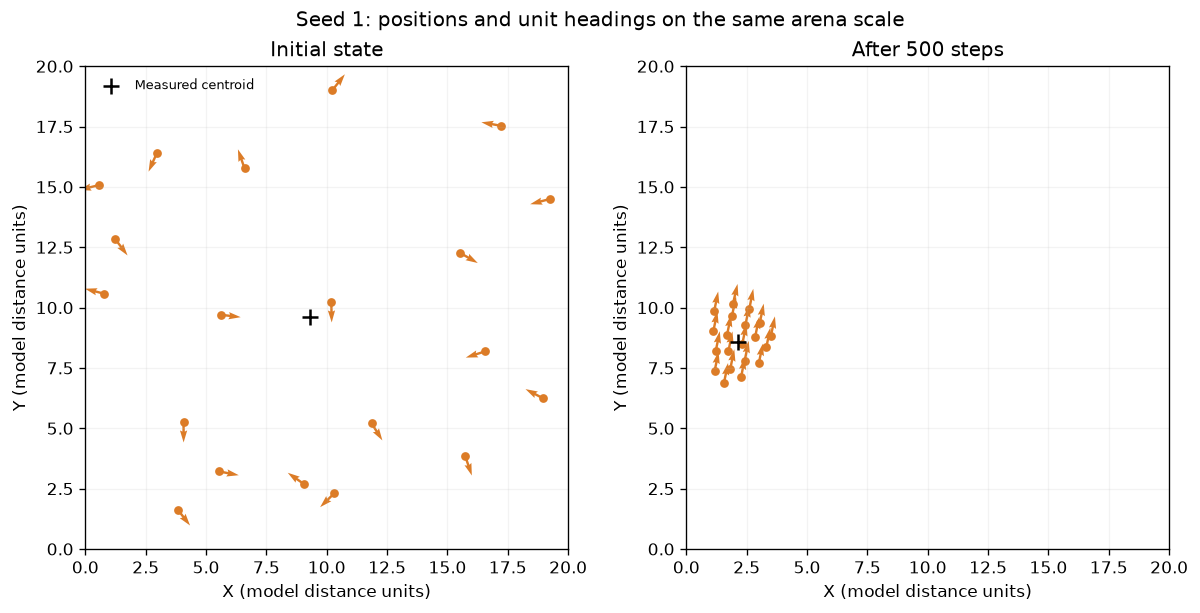

In [5]:
selected_agents = selected_model.datacollector.get_agent_vars_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for axis, step, title in zip(axes, [0, STEPS], ["Initial state", "After 500 steps"]):
    frame = selected_agents.xs(step, level="Step")
    axis.scatter(frame["X"], frame["Y"], color=colors[SELECTED_SEED], s=18)
    axis.quiver(frame["X"], frame["Y"], frame["DirX"], frame["DirY"],
                angles="xy", scale_units="xy", scale=1.2, color=colors[SELECTED_SEED], width=0.005)
    centroid = frame[["X", "Y"]].mean()
    axis.scatter(centroid["X"], centroid["Y"], marker="+", s=100, color="black", label="Measured centroid")
    axis.set(xlim=selected_model.bounds[0], ylim=selected_model.bounds[1],
             xlabel="X (model distance units)", ylabel="Y (model distance units)", title=title)
    axis.set_aspect("equal")
    axis.grid(alpha=0.15)
axes[0].legend(frameon=False, loc="upper left", fontsize=8)
fig.suptitle("Seed 1: positions and unit headings on the same arena scale")
fig.savefig(FIGURE_DIR / "06_initial_final_positions.png", dpi=180)
plt.show()

In [6]:
plot_summary = []
for seed, frame in plot_frames.items():
    final = frame.iloc[-1]
    late = frame.tail(100)
    plot_summary.append({
        "Seed": seed,
        "Late mean polarization": late["Polarization"].mean(),
        "Late mean rotation": late["Rotation"].mean(),
        "Initial group radius": frame.iloc[0]["MeanDistanceToCentroid"],
        "Final group radius": final["MeanDistanceToCentroid"],
        "Final state": final["CollectiveState"],
    })
plot_summary = pd.DataFrame(plot_summary).set_index("Seed")
plot_summary.round(4)

,Late mean polarization,Late mean rotation,Initial group radius,Final group radius,Final state
Seed,,,,,
0,0.4564,0.4319,7.4345,5.5914,transition
1,0.9423,0.0577,7.8211,1.1242,polarized
7,0.9327,0.0402,7.8191,1.1707,polarized


In [7]:
selected_initial = selected.iloc[0]
selected_final = selected.iloc[-1]
late_rotation = plot_summary["Late mean rotation"]
seed_zero_late = plot_frames[0].tail(100)
display(Markdown(f"""## What the plots tell us

- Seed 1 changes from group radius **{selected_initial['MeanDistanceToCentroid']:.3f}** to **{selected_final['MeanDistanceToCentroid']:.3f}**, and finishes with P = **{selected_final['Polarization']:.3f}**, R = **{selected_final['Rotation']:.3f}** (`{selected_final['CollectiveState']}`). The initial/final position panels provide a direct spatial check on that radius change.
- Across the three displayed seeds, late-window mean rotation ranges from **{late_rotation.min():.3f} to {late_rotation.max():.3f}**. Persistent milling would require sustained high rotation with low polarization; that claim should be judged from the curves and state-space trajectory.
- Seed 0 is the clear compactness exception in this panel: its late-window mean group radius is **{seed_zero_late['MeanDistanceToCentroid'].mean():.3f}** while mean nearest-neighbour distance is **{seed_zero_late['MeanNND'].mean():.3f}**. Small local spacing therefore does not establish one compact whole group. Check 4 includes a final interaction-graph diagnostic to distinguish disconnected clusters from a connected configuration; radius alone does not prove fragmentation.
- All 501 records per seed passed completeness, finite-value, heading and boundary checks. These plots therefore display checked recorded states, including the initial condition, rather than interpolated animation frames.
- Abrupt direction changes are permitted by the current instantaneous-turn rule. If these appear as abrupt changes in order, they identify a modelling assumption to revisit rather than automatically indicating a collection error.

**Before light:** retain these plots as a baseline, resolve any unacceptable seed dependence or wall-dominated behaviour, and decide how to handle perception, turning and social noise. Light-dependent speed will add a new mechanism, so comparing its future plots to this constant-speed baseline will be informative. The plots here do not establish gradient sensing or biological calibration.

The three figures are also saved as PNG files in `figures/` for inspection outside the notebook.
"""))

## What the plots tell us

- Seed 1 changes from group radius **7.821** to **1.124**, and finishes with P = **1.000**, R = **0.036** (`polarized`). The initial/final position panels provide a direct spatial check on that radius change.
- Across the three displayed seeds, late-window mean rotation ranges from **0.040 to 0.432**. Persistent milling would require sustained high rotation with low polarization; that claim should be judged from the curves and state-space trajectory.
- Seed 0 is the clear compactness exception in this panel: its late-window mean group radius is **9.865** while mean nearest-neighbour distance is **0.584**. Small local spacing therefore does not establish one compact whole group. Check 4 includes a final interaction-graph diagnostic to distinguish disconnected clusters from a connected configuration; radius alone does not prove fragmentation.
- All 501 records per seed passed completeness, finite-value, heading and boundary checks. These plots therefore display checked recorded states, including the initial condition, rather than interpolated animation frames.
- Abrupt direction changes are permitted by the current instantaneous-turn rule. If these appear as abrupt changes in order, they identify a modelling assumption to revisit rather than automatically indicating a collection error.

**Before light:** retain these plots as a baseline, resolve any unacceptable seed dependence or wall-dominated behaviour, and decide how to handle perception, turning and social noise. Light-dependent speed will add a new mechanism, so comparing its future plots to this constant-speed baseline will be informative. The plots here do not establish gradient sensing or biological calibration.

The three figures are also saved as PNG files in `figures/` for inspection outside the notebook.
